# 05 · Fantasy Team Picker: You vs the Machine

**How to play**
1. Choose `SEASON` and `GW`.
2. Use the scouting table and `pl.find_player(pool, "name")` to build a squad that follows the FPL rules:
   - 15 players: 2 GK, 5 DEF, 5 MID, 3 FWD
   - total price £100m or less (prices are the real FPL prices in that gameweek)
   - at most 3 players from one club
   - a starting XI of 11 (1 GK, 3-5 DEF, 2-5 MID, 1-3 FWD) and a captain (double points)
3. Run the reveal cell. Both teams score their **real FPL points** for that gameweek.

**What the machine does:** a gradient-boosting model predicts every player's points for the gameweek from their
last 5 gameweeks (points, minutes, goals, assists, bonus, ICT), price, position, and the fixture: team and opponent
Elo, and expected goals for and against. Then it builds the best squad it can afford.
It is trained only on seasons before `SEASON`.

**Simplifications:** every gameweek is a fresh pick (no transfers or chips), and there are no automatic substitutions,
so a starter who doesn't play scores 0.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # run from notebooks/, so "src" is one folder up
from src import pl

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)

In [2]:
# ---- settings ----
SEASON = "2025-26"
GW = 1
PLAYER = "You"

In [3]:
mdf, team_games, elo_hist = pl.build_match_table()
lam = pl.walk_forward_lambdas(mdf)
pgw = pl.build_player_gameweeks(pl.add_fixture_context(pl.load_fpl(), lam))

model = pl.fit_player_model(pgw, SEASON)
assert pgw.loc[pgw["Season"] < SEASON, "Season"].max() < SEASON    # no leakage: only earlier seasons
print("trained on", (pgw["Season"] < SEASON).sum(), "player-gameweeks")

pool = pgw[(pgw["Season"] == SEASON) & (pgw["GW"] == GW)].copy()
pool["Pred"] = model.predict(pool[pl.PLAYER_FEATURES])
print(len(pool), "players have a fixture in gameweek", GW)

trained on 215087 player-gameweeks
690 players have a fixture in gameweek 1


### Scouting: the best players by recent form (points per gameweek over their last 5)

In [4]:
scout = pool.assign(Form=pool["Points_Last5"].round(1))[["Name", "Position", "Team", "Price", "Form", "N_Fix"]]
for pos in ["GK", "DEF", "MID", "FWD"]:
    print(f"--- {pos}")
    print(scout[scout["Position"] == pos].sort_values("Form", ascending=False).head(8).to_string(index=False))

--- GK
                     Name Position           Team  Price  Form  N_Fix
          Jordan Pickford       GK        Everton    5.5   5.2      1
 Emiliano Martínez Romero       GK    Aston Villa    5.0   5.0      1
     Robert Lynch Sánchez       GK        Chelsea    5.0   5.0      1
           Dean Henderson       GK Crystal Palace    5.0   4.4      1
                Nick Pope       GK      Newcastle    5.0   4.2      1
Ederson Santana de Moraes       GK       Man City    5.5   4.0      1
      José Malheiro de Sá       GK         Wolves    4.5   3.8      1
        David Raya Martín       GK        Arsenal    5.5   3.8      1
--- DEF
                            Name Position        Team  Price  Form  N_Fix
Rúben dos Santos Gato Alves Dias      DEF    Man City    5.5   6.8      1
           Marc Cucurella Saseta      DEF     Chelsea    6.0   6.4      1
                  Joško Gvardiol      DEF    Man City    6.0   6.2      1
                   Matheus Nunes      DEF    Man City    5.

In [5]:
# search for anyone by name
pl.find_player(pool.drop(columns="Pred"), "salah")

,Name,Web_Name,Position,Team,Price
215162,Mohamed Salah,M.Salah,MID,Liverpool,14.5


### Your team (this example squad was picked by recent form only; change it!)

In [6]:
my_squad = [
    "Jarrod Bowen",
    "Eberechi Eze",
    "Leandro Trossard",
    "Kevin Schade",
    "Martin Ødegaard",
    "Rúben dos Santos Gato Alves Dias",
    "Antoine Semenyo",
    "Marc Cucurella Saseta",
    "Joško Gvardiol",
    "Ollie Watkins",
    "Jordan Pickford",
    "Václav Hladký",
    "Nathaniel Clyne",
    "Benjamin Fredrick",
    "Leon Chiwome",
]
my_bench = ["Václav Hladký", "Nathaniel Clyne", "Benjamin Fredrick", "Leon Chiwome"]                # the 4 squad players who do NOT start
my_captain = "Jarrod Bowen"

In [7]:
squad_ids = pl.resolve_players(pool, my_squad)
bench_ids = pl.resolve_players(pool, my_bench)
xi_ids = [p for p in squad_ids if p not in bench_ids]
captain_id = pl.resolve_players(pool, [my_captain])[0]

problems = pl.validate_squad(pool, squad_ids, xi_ids, captain_id)
cost = pool[pool["Player_ID"].isin(squad_ids)]["Price"].sum()
print(f"Squad cost: £{cost:.1f}m")
print("Team is valid!" if not problems else "Fix these:\n- " + "\n- ".join(problems))

Squad cost: £93.0m
Team is valid!


### Machine's team

In [8]:
m_squad = pl.machine_squad(pool)
m_xi, m_captain = pl.best_xi(pool[pool["Player_ID"].isin(m_squad)])
assert not pl.validate_squad(pool, m_squad, m_xi, m_captain)
print(f"Machine squad cost: £{pool[pool['Player_ID'].isin(m_squad)]['Price'].sum():.1f}m")

Machine squad cost: £100.0m


### Reveal

In [9]:
assert not problems, "your team breaks the rules: see the check above"

def show(xi, captain):
    t = pool[pool["Player_ID"].isin(xi)].copy()
    t["C"] = np.where(t["Player_ID"] == captain, "C", "")
    t["Pred"] = t["Pred"].round(1)
    order = {"GK": 0, "DEF": 1, "MID": 2, "FWD": 3}
    return t.sort_values("Position", key=lambda s: s.map(order))[["Name", "Position", "Team", "Price", "C", "Pred", "Points"]]

you_pts = pl.team_points(pool, xi_ids, captain_id)
machine_pts = pl.team_points(pool, m_xi, m_captain)
best = pool.sort_values("Points", ascending=False).iloc[0]
print(f"Gameweek {GW}:  {PLAYER} {you_pts} pts  |  Machine {machine_pts} pts")
print(f"Top scorer of the week: {best['Name']} ({best['Team']}) with {best['Points']} pts\n")
print("YOUR XI"); print(show(xi_ids, captain_id).to_string(index=False))
print("\nMACHINE XI"); print(show(m_xi, m_captain).to_string(index=False))

Gameweek 1:  You 46 pts  |  Machine 41 pts
Top scorer of the week: Daniel Ballard (Sunderland) with 17 pts

YOUR XI
                            Name Position           Team  Price C  Pred  Points
                 Jordan Pickford       GK        Everton    5.5     3.5       2
Rúben dos Santos Gato Alves Dias      DEF       Man City    5.5     3.3       6
           Marc Cucurella Saseta      DEF        Chelsea    6.0     3.2       8
                  Joško Gvardiol      DEF       Man City    6.0     3.5       0
                    Eberechi Eze      MID Crystal Palace    7.5     3.2       3
                 Martin Ødegaard      MID        Arsenal    8.0     3.4       5
                 Antoine Semenyo      MID    Bournemouth    7.0     2.6      15
                Leandro Trossard      MID        Arsenal    7.0     3.3       0
                    Kevin Schade      MID      Brentford    7.0     3.2       1
                    Jarrod Bowen      FWD       West Ham    8.0 C   8.4       2
    

In [10]:
log = pd.DataFrame([{"Season": SEASON, "GW": GW, "Player": PLAYER, "Points": you_pts},
                    {"Season": SEASON, "GW": GW, "Player": "Machine", "Points": machine_pts}])
history = pl.save_results(log, "fantasy.csv", keys=["Season", "GW", "Player"])
season_log = history[history["Season"] == SEASON]
print(season_log.pivot_table(index="GW", columns="Player", values="Points", aggfunc="sum").assign().to_string())
print("\nTotal:", season_log.groupby("Player")["Points"].sum().to_dict())

Player  Machine  You
GW                  
1            41   46

Total: {'Machine': 41, 'You': 46}


## How good is the machine? (model report)

1. **Prediction error** over the whole season: mean absolute error (MAE) of the model, compared with simply
   using a player's last-5 average.
2. **A full season of the game**: the machine picks a team every gameweek. It is compared with a "form" manager
   who uses the same squad-building method but ranks players by last-5 points instead of the model.

MAE model:           0.999
MAE last-5 average:  1.068


Machine         2207
Form manager    1749


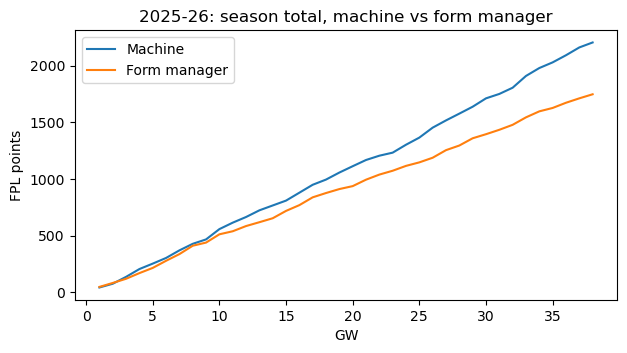

In [11]:
from sklearn.metrics import mean_absolute_error

season_rows = pgw[pgw["Season"] == SEASON].copy()
season_rows["Pred"] = model.predict(season_rows[pl.PLAYER_FEATURES])
season_rows["Form"] = season_rows["Points_Last5"].fillna(0)
print("MAE model:          ", round(mean_absolute_error(season_rows["Points"], season_rows["Pred"]), 3))
print("MAE last-5 average: ", round(mean_absolute_error(season_rows["Points"], season_rows["Form"]), 3))

rows = []
for gw, p in season_rows.groupby("GW"):
    row = {"GW": gw}
    for name, col in [("Machine", "Pred"), ("Form manager", "Form")]:
        sq = pl.machine_squad(p, col=col)
        xi, cap = pl.best_xi(p[p["Player_ID"].isin(sq)], col=col)
        row[name] = pl.team_points(p, xi, cap)
    rows.append(row)
season_game = pd.DataFrame(rows).set_index("GW")
print(season_game.sum().to_string())
ax = season_game.cumsum().plot(figsize=(7, 3.5), title=f"{SEASON}: season total, machine vs form manager")
ax.set_ylabel("FPL points")
plt.show()